# Quantum Variational Circuits (VQC)

This Notebook provides an introduction to Variational Quantum Circuits (VQCs), also known as Parameterized Quantum Circuits (PQCs). VQCs are fundamental building blocks in quantum machine learning and variational quantum algorithms.


## 1. Introduction to Variational Quantum Circuits

### What is a VQC?

A **Variational Quantum Circuit (VQC)** is a quantum circuit that contains **parameterized gates** (gates with adjustable parameters). These parameters are optimized using classical optimization algorithms to minimize or maximize a cost function.

### Key Components:

1. **Parameterized Gates**: Quantum gates with tunable parameters (e.g., rotation angles)
2. **Cost Function**: A function that measures how well the circuit performs
3. **Optimizer**: A classical algorithm that adjusts parameters to minimize the cost

### Why VQCs Matter:

- **Hybrid Quantum-Classical Computing**: Combines quantum circuits with classical optimization
- **Noise Resilience**: Can work on near-term quantum hardware
- **Flexibility**: Can be adapted for various tasks (optimization, machine learning, chemistry)

### Simple Example:

We'll create a simple VQC with 1-2 qubits that learns to prepare a target quantum state.

## 2. Setup and Imports


In [22]:
pip install qiskit qiskit-aer pylatexenc matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 13.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 101.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 84.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 107.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 6.2 MB/s eta 0:00:00
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=f3be1de4eacf1446846794eff6e110eeaab2064d6ca5719e3a66f96a096a03ae
  Stored in directory: /root/.cache/pip/wheels/06/3e/78/fa1588c1ae991bbfd814af2bcac6cef7a178beee1939180d46
Successfully built pylatexenc


In [23]:
# Import Qiskit components
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.circuit import Parameter

# Import optimization and numerical libraries
import numpy as np
from scipy.optimize import minimize

# Import visualization tools
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Building a Simple 1-Qubit Variational Circuit

Let's start with the simplest case: a 1-qubit variational circuit. We'll use rotation gates with parameters that we can optimize.

1-Qubit Variational Circuit:
   ┌───────┐
q: ┤ Ry(θ) ├
   └───────┘


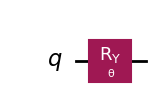

In [24]:
# Create a parameter for our variational circuit
theta = Parameter('θ')  # This is a parameter we'll optimize

# Create a simple 1-qubit variational circuit
qc_1qubit = QuantumCircuit(1)

# Add parameterized rotation around Y-axis
# This gate rotates the qubit state by angle theta
qc_1qubit.ry(theta, 0)

# Visualize the circuit
print("1-Qubit Variational Circuit:")
print(qc_1qubit)
qc_1qubit.draw('mpl')

### Understanding the Circuit

- **Parameter θ**: This is what we'll optimize
- **RY gate**: Rotates the qubit around the Y-axis by angle θ
- The circuit starts with |0⟩ and applies the rotation

The state after the rotation is: |ψ(θ)⟩ = cos(θ/2)|0⟩ + sin(θ/2)|1⟩

## 4. Defining a Cost Function

A cost function tells us how "good" our circuit is. We'll define a simple goal: prepare a target state.

For this example, let's try to prepare the state |+⟩ = (|0⟩ + |1⟩)/√2, which corresponds to θ = π/2.

In [25]:
# Define the target state |+⟩ = (|0⟩ + |1⟩)/√2
target_state = Statevector([1/np.sqrt(2), 1/np.sqrt(2)])

print("Target state |+⟩:")
print(target_state)

Target state |+⟩:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))


In [26]:
def cost_function_1qubit(theta_value):
    """
    Calculate the cost: how far is our state from the target state?

    We use the fidelity (overlap) between states:
    F = |⟨target|ψ(θ)⟩|²
    Cost = 1 - F (we want to minimize this)
    """
    # Assign the parameter to a specific value
    qc_bound = qc_1qubit.assign_parameters({theta: theta_value})




    # Get the statevector directly from the circuit
    # This is more efficient than running a simulator
    state = Statevector.from_instruction(qc_bound)

    # Calculate fidelity (overlap squared)
    fidelity = abs(state.inner(target_state))**2

    # Return cost (1 - fidelity, so we minimize to maximize fidelity)
    return 1 - fidelity

# Test the cost function with a random parameter
test_theta = 0.5
test_cost = cost_function_1qubit(test_theta)
print(f"Cost for θ = {test_theta}: {test_cost:.4f}")
print(f"Fidelity: {1 - test_cost:.4f}")

Cost for θ = 0.5: 0.2603
Fidelity: 0.7397


## 5. Optimizing the Parameters

Now let's use a classical optimizer to find the best value of θ that minimizes our cost function.

In [27]:
# Initial guess for theta (random starting point)
initial_theta = np.random.uniform(0, 2*np.pi)

print(f"Starting optimization with initial θ = {initial_theta:.4f}")
print(f"Initial cost: {cost_function_1qubit(initial_theta):.4f}")

# Use scipy's minimize function to find optimal theta
result = minimize(cost_function_1qubit, initial_theta, method='BFGS')

optimal_theta = result.x[0]
optimal_cost = result.fun

print(f"\nOptimization complete!")
print(f"Optimal θ = {optimal_theta:.4f} radians")
print(f"Optimal θ = {np.degrees(optimal_theta):.2f} degrees")
print(f"Final cost: {optimal_cost:.6f}")
print(f"Final fidelity: {1 - optimal_cost:.6f}")
print(f"\nExpected optimal θ = π/2 = {np.pi/2:.4f} radians")

Starting optimization with initial θ = 3.5921
Initial cost: 0.7177

Optimization complete!
Optimal θ = 1.5708 radians
Optimal θ = 90.00 degrees
Final cost: 0.000000
Final fidelity: 1.000000

Expected optimal θ = π/2 = 1.5708 radians


## 6. Visualizing the Results

Let's visualize how the cost function changes with different values of θ, and verify our optimized state.

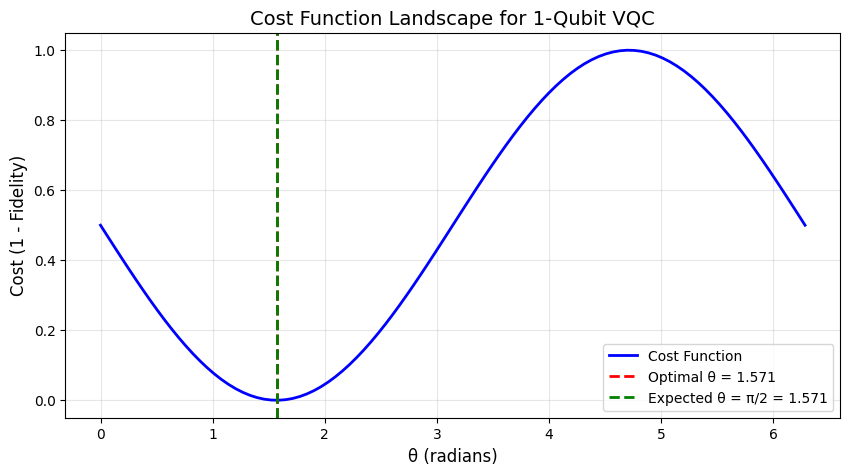

In [28]:
# Plot the cost function landscape
theta_range = np.linspace(0, 2*np.pi, 100)
costs = [cost_function_1qubit(t) for t in theta_range]

plt.figure(figsize=(10, 5))
plt.plot(theta_range, costs, 'b-', linewidth=2, label='Cost Function')
plt.axvline(optimal_theta%(2*np.pi), color='r', linestyle='--', linewidth=2, label=f'Optimal θ = {optimal_theta:.3f}')
plt.axvline(np.pi/2, color='g', linestyle='--', linewidth=2, label=f'Expected θ = π/2 = {np.pi/2:.3f}')
plt.xlabel('θ (radians)', fontsize=12)
plt.ylabel('Cost (1 - Fidelity)', fontsize=12)
plt.title('Cost Function Landscape for 1-Qubit VQC', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [29]:
# Verify the final state
qc_final = qc_1qubit.assign_parameters({theta: optimal_theta})


final_state = Statevector.from_instruction(qc_final)

print("Final state from optimized circuit:")
print(final_state)
print("\nTarget state:")
print(target_state)
print(f"\nFidelity: {abs(final_state.inner(target_state))**2:.6f}")

Final state from optimized circuit:
Statevector([0.70710665+0.j, 0.70710692+0.j],
            dims=(2,))

Target state:
Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))

Fidelity: 1.000000


## 7. Building a 2-Qubit Variational Circuit

Now let's create a more interesting example with 2 qubits. This will demonstrate entanglement and more complex parameterized circuits.

2-Qubit Variational Circuit:
     ┌────────┐     ┌───────┐
q_0: ┤ Ry(θ₁) ├──■──┤ Ry(φ) ├
     ├────────┤┌─┴─┐└───────┘
q_1: ┤ Ry(θ₂) ├┤ X ├─────────
     └────────┘└───┘         


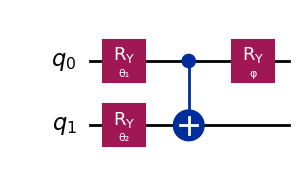

In [30]:
# Create parameters for our 2-qubit circuit
theta1 = Parameter('θ₁')
theta2 = Parameter('θ₂')
phi = Parameter('φ')

# Create a 2-qubit variational circuit
qc_2qubit = QuantumCircuit(2)

# Apply parameterized rotations to each qubit
qc_2qubit.ry(theta1, 0)  # Rotate first qubit
qc_2qubit.ry(theta2, 1)  # Rotate second qubit

# Add an entangling gate (CNOT)
qc_2qubit.cx(0, 1)

# Add another parameterized rotation
qc_2qubit.ry(phi, 0)

print("2-Qubit Variational Circuit:")
print(qc_2qubit)
qc_2qubit.draw('mpl')

### Understanding the 2-Qubit Circuit

- **θ₁, θ₂**: Rotations on individual qubits
- **CNOT**: Creates entanglement between qubits
- **φ**: Additional rotation after entanglement

This circuit can create entangled states and has more expressive power than the 1-qubit case.

## 8. Cost Function for 2-Qubit Circuit

Let's define a target state for our 2-qubit circuit. We'll try to prepare a Bell state: |Φ⁺⟩ = (|00⟩ + |11⟩)/√2

In [31]:
# Define the target Bell state |Φ⁺⟩ = (|00⟩ + |11⟩)/√2
target_bell = Statevector([1/np.sqrt(2), 0, 0, 1/np.sqrt(2)])

print("Target Bell state |Φ⁺⟩:")
print(target_bell)

Target Bell state |Φ⁺⟩:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


In [32]:
def cost_function_2qubit(params):
    """
    Calculate the cost for the 2-qubit circuit.

    params: array [theta1, theta2, phi]
    """
    theta1_val, theta2_val, phi_val = params

    # Assign parameters to the circuit
    qc_bound = qc_2qubit.assign_parameters({
        theta1: theta1_val,
        theta2: theta2_val,
        phi: phi_val
    })




    # Get the statevector directly from the circuit
    # This is more efficient than running a simulator
    state = Statevector.from_instruction(qc_bound)

    # Calculate fidelity
    fidelity = abs(state.inner(target_bell))**2

    # Return cost
    return 1 - fidelity

# Test with random parameters
test_params = np.random.uniform(0, 2*np.pi, 3)
test_cost = cost_function_2qubit(test_params)
print(f"Test parameters: θ₁={test_params[0]:.3f}, θ₂={test_params[1]:.3f}, φ={test_params[2]:.3f}")
print(f"Cost: {test_cost:.4f}, Fidelity: {1 - test_cost:.4f}")

Test parameters: θ₁=5.722, θ₂=1.339, φ=4.201
Cost: 0.9231, Fidelity: 0.0769


## 9. Optimizing the 2-Qubit Circuit

Now let's optimize all three parameters to prepare the Bell state.

In [33]:
# Initial guess for all three parameters
initial_params = np.random.uniform(0, 2*np.pi, 3)

print("Starting optimization for 2-qubit circuit:")
print(f"Initial parameters: θ₁={initial_params[0]:.4f}, θ₂={initial_params[1]:.4f}, φ={initial_params[2]:.4f}")
print(f"Initial cost: {cost_function_2qubit(initial_params):.4f}")

# Optimize
result = minimize(cost_function_2qubit, initial_params, method='BFGS')

optimal_params = result.x
optimal_cost = result.fun

print(f"\nOptimization complete!")
print(f"Optimal θ₁ = {optimal_params[0]:.4f} radians ({np.degrees(optimal_params[0]):.2f}°)")
print(f"Optimal θ₂ = {optimal_params[1]:.4f} radians ({np.degrees(optimal_params[1]):.2f}°)")
print(f"Optimal φ = {optimal_params[2]:.4f} radians ({np.degrees(optimal_params[2]):.2f}°)")
print(f"Final cost: {optimal_cost:.6f}")
print(f"Final fidelity: {1 - optimal_cost:.6f}")

Starting optimization for 2-qubit circuit:
Initial parameters: θ₁=6.1782, θ₂=1.9297, φ=2.1736
Initial cost: 0.4844

Optimization complete!
Optimal θ₁ = 4.7124 radians (270.00°)
Optimal θ₂ = 3.1416 radians (180.00°)
Optimal φ = 3.1416 radians (180.00°)
Final cost: 0.000000
Final fidelity: 1.000000


In [34]:
# Verify the final state
qc_final_2qubit = qc_2qubit.assign_parameters({
    theta1: optimal_params[0],
    theta2: optimal_params[1],
    phi: optimal_params[2]
})



final_state_2qubit = Statevector.from_instruction(qc_final_2qubit)

print("Final state from optimized 2-qubit circuit:")
print(final_state_2qubit)
print("\nTarget Bell state |Φ⁺⟩:")
print(target_bell)
print(f"\nFidelity: {abs(final_state_2qubit.inner(target_bell))**2:.6f}")

Final state from optimized 2-qubit circuit:
Statevector([-7.07106313e-01+0.j, -2.20157901e-06+0.j,  1.40526592e-06+0.j,
             -7.07107249e-01+0.j],
            dims=(2, 2))

Target Bell state |Φ⁺⟩:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))

Fidelity: 1.000000


## 10. Visualizing the 2-Qubit Circuit Evolution

Let's see how the optimization process works by tracking the cost during optimization.

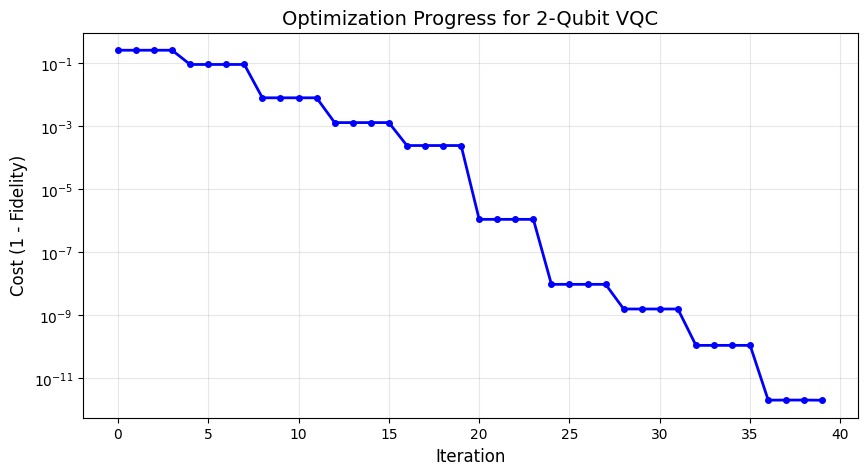

Converged after 40 iterations
Final cost: 0.000000


In [35]:
# Track optimization progress
cost_history = []

def cost_with_history(params):
    """Wrapper to track cost during optimization"""
    cost = cost_function_2qubit(params)
    cost_history.append(cost)
    return cost

# Reset history and optimize again
cost_history = []
initial_params = np.random.uniform(0, 2*np.pi, 3)
result = minimize(cost_with_history, initial_params, method='BFGS', options={'maxiter': 50})

# Plot optimization progress
plt.figure(figsize=(10, 5))
plt.plot(cost_history, 'b-', linewidth=2, marker='o', markersize=4)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Cost (1 - Fidelity)', fontsize=12)
plt.title('Optimization Progress for 2-Qubit VQC', fontsize=14)
plt.grid(True, alpha=0.3)
plt.yscale('log')  # Use log scale to see convergence better
plt.show()

print(f"Converged after {len(cost_history)} iterations")
print(f"Final cost: {cost_history[-1]:.6f}")

## 11. Summary and Key Takeaways

### What We Learned:

1. **Variational Quantum Circuits** use parameterized gates that can be optimized
2. **Cost Functions** measure how well the circuit performs (we used state fidelity)
3. **Classical Optimizers** (like BFGS) find optimal parameter values
4. **Hybrid Approach** combines quantum circuits with classical optimization

### Key Concepts:

- **Parameters**: Adjustable angles in rotation gates
- **Fidelity**: Measure of how close two quantum states are (0 to 1)
- **Optimization**: Finding parameters that minimize the cost function
- **Entanglement**: 2-qubit circuits can create entangled states

### Next Steps:

- Try different target states
- Experiment with different circuit architectures
- Use different optimizers (SPSA, COBYLA, etc.)
- Apply VQCs to real problems (optimization, machine learning, chemistry)

### Applications of VQCs:

- **Variational Quantum Eigensolver (VQE)**: Finding ground states of molecules
- **Quantum Machine Learning**: Training quantum neural networks
- **Quantum Optimization**: Solving combinatorial optimization problems
- **Quantum Chemistry**: Simulating molecular systems
